# Projeto Final - Etapa 2: Pré-processamento e Análise Exploratória dos Dados (EDA)

Este notebook realiza a **Etapa 2 do projeto final** com a base `estudantes_desempenho.CSV`.

Objetivos: verificar a estrutura e qualidade dos dados, valores ausentes, duplicidades, tipos e inconsistências; analisar notas, faltas, tempo de estudo e reprovações; estudar relações com o desempenho; e preparar codificação e padronização para modelagem.

**Decisão adotada:** notas finais iguais a zero serão mantidas como valores válidos nesta etapa e não serão recalculadas.


## 2.1 Importação das bibliotecas

Usaremos `pandas` para manipulação, `numpy` para operações numéricas e `matplotlib`/`seaborn` para visualização.


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler


pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


## 2.2 Carregamento do CSV

O arquivo utiliza ponto e vírgula (`;`) como separador.


In [9]:
arquivo = "estudantes_desempenho.CSV"
df = pd.read_csv(arquivo, sep=";", encoding="latin-1")
df.head()


,Escola,Sexo,Idade,Tipo_de_Endereco,Tamanho_da_Familia,Situacao_dos_Pais,Escolaridade_da_Mae,Escolaridade_do_Pai,Ocupacao_da_Mae,Ocupacao_do_Pai,Motivo_da_Escolha_da_Escola,Responsavel,Tempo_de_Deslocamento,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Apoio_Educacional_da_Escola,Apoio_Educacional_Familiar,Aulas_Particulares_Pagas,Atividades_Extracurriculares,Frequentou_Educacao_Infantil,Pretende_Cursar_Ensino_Superior,Acesso_a_Internet_em_Casa,Relacionamento_Amoroso,Qualidade_das_Relacoes_Familiares,Tempo_Livre_Apos_a_Escola,Frequencia_de_Saidas_com_Amigos,Consumo_de_Alcool_em_Dias_Uteis,Consumo_de_Alcool_no_Fim_de_Semana,Estado_de_Saude_Atual,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
0,GP,Feminino,18,Urbano,Mais_de_3,Separados,4,4,Em_casa,Professor(a),Preferencia_pelo_curso,Mae,2,2,0,Sim,Não,Não,Não,Sim,Sim,Não,Não,4,3,4,1,1,3,4,0,11,11
1,GP,Feminino,17,Urbano,Mais_de_3,Juntos,1,1,Em_casa,Outro,Preferencia_pelo_curso,Pai,1,2,0,Não,Sim,Não,Não,Não,Sim,Sim,Não,5,3,3,1,1,3,2,9,11,11
2,GP,Feminino,15,Urbano,Ate_3,Juntos,1,1,Em_casa,Outro,Outro,Mae,1,2,0,Sim,Não,Não,Não,Sim,Sim,Sim,Não,4,3,2,2,3,3,6,12,13,12
3,GP,Feminino,15,Urbano,Mais_de_3,Juntos,4,2,Saude,Servicos,Proximidade_de_casa,Mae,1,3,0,Não,Sim,Não,Sim,Sim,Sim,Sim,Sim,3,2,2,1,1,5,0,14,14,14
4,GP,Feminino,16,Urbano,Mais_de_3,Juntos,3,3,Outro,Outro,Proximidade_de_casa,Pai,1,2,0,Não,Sim,Não,Não,Sim,Sim,Não,Não,4,3,2,1,2,5,0,11,13,13


## 2.3 Dimensão e conferência da base

Cada linha representa um estudante e cada coluna uma característica.


In [10]:
print(f"A base possui {df.shape[0]} estudantes.")
print(f"A base possui {df.shape[1]} variáveis.")
df.sample(5, random_state=42)


A base possui 649 estudantes.
A base possui 33 variáveis.


,Escola,Sexo,Idade,Tipo_de_Endereco,Tamanho_da_Familia,Situacao_dos_Pais,Escolaridade_da_Mae,Escolaridade_do_Pai,Ocupacao_da_Mae,Ocupacao_do_Pai,Motivo_da_Escolha_da_Escola,Responsavel,Tempo_de_Deslocamento,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Apoio_Educacional_da_Escola,Apoio_Educacional_Familiar,Aulas_Particulares_Pagas,Atividades_Extracurriculares,Frequentou_Educacao_Infantil,Pretende_Cursar_Ensino_Superior,Acesso_a_Internet_em_Casa,Relacionamento_Amoroso,Qualidade_das_Relacoes_Familiares,Tempo_Livre_Apos_a_Escola,Frequencia_de_Saidas_com_Amigos,Consumo_de_Alcool_em_Dias_Uteis,Consumo_de_Alcool_no_Fim_de_Semana,Estado_de_Saude_Atual,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
636,MS,Masculino,18,Urbano,Mais_de_3,Juntos,4,4,Professor(a),Professor(a),Proximidade_de_casa,Pai,1,2,0,Não,Não,Não,Sim,Não,Sim,Sim,Não,3,2,4,1,4,2,4,17,18,19
220,GP,Feminino,16,Urbano,Mais_de_3,Separados,3,1,Servicos,Outro,Preferencia_pelo_curso,Mae,1,2,0,Não,Sim,Não,Não,Sim,Sim,Sim,Não,2,3,3,2,2,4,2,11,11,12
594,MS,Feminino,18,Urbano,Mais_de_3,Juntos,4,4,Professor(a),Professor(a),Reputacao_da_escola,Mae,2,2,0,Não,Não,Não,Sim,Não,Sim,Sim,Não,4,3,5,1,2,1,0,18,18,18
429,MS,Masculino,16,Rural,Ate_3,Separados,4,4,Em_casa,Outro,Proximidade_de_casa,Mae,1,2,0,Não,Sim,Não,Não,Sim,Sim,Não,Não,5,3,2,1,3,2,5,10,11,11
72,GP,Feminino,15,Rural,Mais_de_3,Juntos,1,1,Outro,Outro,Reputacao_da_escola,Mae,1,2,0,Sim,Sim,Não,Não,Não,Sim,Sim,Sim,3,3,4,2,4,5,2,13,11,11


## 2.4 Colunas e tipos das variáveis

Removemos espaços externos dos nomes e observamos os tipos. Algumas colunas numéricas são categorias ordinais e devem ser interpretadas segundo suas escalas.


In [11]:
df.columns = df.columns.str.strip()
for numero, coluna in enumerate(df.columns, 1):
    print(f"{numero}: {coluna}")


1: Escola
2: Sexo
3: Idade
4: Tipo_de_Endereco
5: Tamanho_da_Familia
6: Situacao_dos_Pais
7: Escolaridade_da_Mae
8: Escolaridade_do_Pai
9: Ocupacao_da_Mae
10: Ocupacao_do_Pai
11: Motivo_da_Escolha_da_Escola
12: Responsavel
13: Tempo_de_Deslocamento
14: Tempo_de_Estudo_Semanal
15: Reprovacoes_Anteriores
16: Apoio_Educacional_da_Escola
17: Apoio_Educacional_Familiar
18: Aulas_Particulares_Pagas
19: Atividades_Extracurriculares
20: Frequentou_Educacao_Infantil
21: Pretende_Cursar_Ensino_Superior
22: Acesso_a_Internet_em_Casa
23: Relacionamento_Amoroso
24: Qualidade_das_Relacoes_Familiares
25: Tempo_Livre_Apos_a_Escola
26: Frequencia_de_Saidas_com_Amigos
27: Consumo_de_Alcool_em_Dias_Uteis
28: Consumo_de_Alcool_no_Fim_de_Semana
29: Estado_de_Saude_Atual
30: Numero_de_Faltas
31: Nota_1o_Periodo
32: Nota_2o_Periodo
33: Nota_Final


In [12]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Escola                              649 non-null    object
 1   Sexo                                649 non-null    object
 2   Idade                               649 non-null    int64 
 3   Tipo_de_Endereco                    649 non-null    object
 4   Tamanho_da_Familia                  649 non-null    object
 5   Situacao_dos_Pais                   649 non-null    object
 6   Escolaridade_da_Mae                 649 non-null    int64 
 7   Escolaridade_do_Pai                 649 non-null    int64 
 8   Ocupacao_da_Mae                     649 non-null    object
 9   Ocupacao_do_Pai                     649 non-null    object
 10  Motivo_da_Escolha_da_Escola         649 non-null    object
 11  Responsavel                         649 non-null    object

In [13]:
colunas_numericas = df.select_dtypes(include="number").columns.tolist()
colunas_categoricas = df.select_dtypes(include="object").columns.tolist()
print("Numéricas:", colunas_numericas)
print("Categóricas:", colunas_categoricas)


Numéricas: ['Idade', 'Escolaridade_da_Mae', 'Escolaridade_do_Pai', 'Tempo_de_Deslocamento', 'Tempo_de_Estudo_Semanal', 'Reprovacoes_Anteriores', 'Qualidade_das_Relacoes_Familiares', 'Tempo_Livre_Apos_a_Escola', 'Frequencia_de_Saidas_com_Amigos', 'Consumo_de_Alcool_em_Dias_Uteis', 'Consumo_de_Alcool_no_Fim_de_Semana', 'Estado_de_Saude_Atual', 'Numero_de_Faltas', 'Nota_1o_Periodo', 'Nota_2o_Periodo', 'Nota_Final']
Categóricas: ['Escola', 'Sexo', 'Tipo_de_Endereco', 'Tamanho_da_Familia', 'Situacao_dos_Pais', 'Ocupacao_da_Mae', 'Ocupacao_do_Pai', 'Motivo_da_Escolha_da_Escola', 'Responsavel', 'Apoio_Educacional_da_Escola', 'Apoio_Educacional_Familiar', 'Aulas_Particulares_Pagas', 'Atividades_Extracurriculares', 'Frequentou_Educacao_Infantil', 'Pretende_Cursar_Ensino_Superior', 'Acesso_a_Internet_em_Casa', 'Relacionamento_Amoroso']


## 2.5 Limpeza simples dos textos

Removemos espaços externos e trocamos sublinhados por espaços somente nos valores categóricos para melhorar a leitura.


In [14]:
for coluna in colunas_categoricas:
    df[coluna] = df[coluna].str.strip().str.replace("_", " ", regex=False)


## 2.6 Valores ausentes

Verificamos quantidade e percentual de ausências.


In [15]:
valores_ausentes = df.isnull().sum()
percentual_ausentes = (df.isnull().mean() * 100).round(2)
analise_ausentes = pd.DataFrame({"Quantidade_Ausentes": valores_ausentes, "Percentual_Ausentes": percentual_ausentes})
analise_ausentes = analise_ausentes[analise_ausentes["Quantidade_Ausentes"] > 0].sort_values("Quantidade_Ausentes", ascending=False)
print("Total de valores ausentes:", df.isnull().sum().sum())
analise_ausentes


Total de valores ausentes: 0


,Quantidade_Ausentes,Percentual_Ausentes


### 2.6.1 Ausências representadas como texto

Também pesquisamos marcadores comuns de ausência.


In [16]:
valores_suspeitos = ["", " ", "NA", "N/A", "null", "Null", "?", "-"]
for coluna in colunas_categoricas:
    quantidade = df[coluna].isin(valores_suspeitos).sum()
    if quantidade > 0:
        print(f"{coluna}: {quantidade} valor(es) suspeito(s)")


In [17]:
df.replace(valores_suspeitos, np.nan, inplace=True)
print("Total após a verificação:", df.isnull().sum().sum())


Total após a verificação: 0


## 2.7 Duplicidades

Como não existe identificador do estudante, registros iguais são investigados antes de qualquer exclusão.


In [18]:
quantidade_duplicados = df.duplicated().sum()
print(f"Foram encontradas {quantidade_duplicados} linhas completamente duplicadas.")
df[df.duplicated(keep=False)]


Foram encontradas 0 linhas completamente duplicadas.


,Escola,Sexo,Idade,Tipo_de_Endereco,Tamanho_da_Familia,Situacao_dos_Pais,Escolaridade_da_Mae,Escolaridade_do_Pai,Ocupacao_da_Mae,Ocupacao_do_Pai,Motivo_da_Escolha_da_Escola,Responsavel,Tempo_de_Deslocamento,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Apoio_Educacional_da_Escola,Apoio_Educacional_Familiar,Aulas_Particulares_Pagas,Atividades_Extracurriculares,Frequentou_Educacao_Infantil,Pretende_Cursar_Ensino_Superior,Acesso_a_Internet_em_Casa,Relacionamento_Amoroso,Qualidade_das_Relacoes_Familiares,Tempo_Livre_Apos_a_Escola,Frequencia_de_Saidas_com_Amigos,Consumo_de_Alcool_em_Dias_Uteis,Consumo_de_Alcool_no_Fim_de_Semana,Estado_de_Saude_Atual,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final


## 2.8 Categorias

Verificamos quantas categorias existem e suas frequências.


In [19]:
df[colunas_categoricas].nunique().sort_values()


Escola                             2
Sexo                               2
Tipo_de_Endereco                   2
Tamanho_da_Familia                 2
Situacao_dos_Pais                  2
Aulas_Particulares_Pagas           2
Apoio_Educacional_Familiar         2
Apoio_Educacional_da_Escola        2
Pretende_Cursar_Ensino_Superior    2
Frequentou_Educacao_Infantil       2
Acesso_a_Internet_em_Casa          2
Atividades_Extracurriculares       2
Relacionamento_Amoroso             2
Responsavel                        3
Motivo_da_Escolha_da_Escola        4
Ocupacao_do_Pai                    5
Ocupacao_da_Mae                    5
dtype: int64

In [22]:
for coluna in colunas_categoricas:
    print(" " + "=" * 60)
    print("COLUNA:", coluna)
    print(df[coluna].value_counts(dropna=False))


COLUNA: Escola
Escola
GP    423
MS    226
Name: count, dtype: int64
COLUNA: Sexo
Sexo
Feminino     383
Masculino    266
Name: count, dtype: int64
COLUNA: Tipo_de_Endereco
Tipo_de_Endereco
Urbano    452
Rural     197
Name: count, dtype: int64
COLUNA: Tamanho_da_Familia
Tamanho_da_Familia
Mais de 3    457
Ate 3        192
Name: count, dtype: int64
COLUNA: Situacao_dos_Pais
Situacao_dos_Pais
Juntos       569
Separados     80
Name: count, dtype: int64
COLUNA: Ocupacao_da_Mae
Ocupacao_da_Mae
Outro           258
Servicos        136
Em casa         135
Professor(a)     72
Saude            48
Name: count, dtype: int64
COLUNA: Ocupacao_do_Pai
Ocupacao_do_Pai
Outro           367
Servicos        181
Em casa          42
Professor(a)     36
Saude            23
Name: count, dtype: int64
COLUNA: Motivo_da_Escolha_da_Escola
Motivo_da_Escolha_da_Escola
Preferencia pelo curso    285
Proximidade de casa       149
Reputacao da escola       143
Outro                      72
Name: count, dtype: int64
COLUNA

## 2.9 Estatísticas descritivas

Para variáveis numéricas observamos média, desvio-padrão, mínimo, quartis e máximo.


In [23]:
df.describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
Idade,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Escolaridade_da_Mae,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Escolaridade_do_Pai,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
Tempo_de_Deslocamento,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
Tempo_de_Estudo_Semanal,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
Reprovacoes_Anteriores,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
Qualidade_das_Relacoes_Familiares,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
Tempo_Livre_Apos_a_Escola,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
Frequencia_de_Saidas_com_Amigos,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Consumo_de_Alcool_em_Dias_Uteis,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


Para as categóricas, observamos quantidade, categorias e valor mais frequente.


In [24]:
df.describe(include="object").T


,count,unique,top,freq
Escola,649,2,GP,423
Sexo,649,2,Feminino,383
Tipo_de_Endereco,649,2,Urbano,452
Tamanho_da_Familia,649,2,Mais de 3,457
Situacao_dos_Pais,649,2,Juntos,569
Ocupacao_da_Mae,649,5,Outro,258
Ocupacao_do_Pai,649,5,Outro,367
Motivo_da_Escolha_da_Escola,649,4,Preferencia pelo curso,285
Responsavel,649,3,Mae,455
Apoio_Educacional_da_Escola,649,2,Não,581


### Principais variáveis do estudo


In [25]:
variaveis_principais = ["Idade", "Tempo_de_Deslocamento", "Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores", "Numero_de_Faltas", "Nota_1o_Periodo", "Nota_2o_Periodo", "Nota_Final"]
df[variaveis_principais].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
Idade,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Tempo_de_Deslocamento,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
Tempo_de_Estudo_Semanal,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
Reprovacoes_Anteriores,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
Numero_de_Faltas,649.0,3.66,4.64,0.0,0.0,2.0,6.0,32.0
Nota_1o_Periodo,649.0,11.40,2.75,0.0,10.0,11.0,13.0,19.0
Nota_2o_Periodo,649.0,11.57,2.91,0.0,10.0,11.0,13.0,19.0
Nota_Final,649.0,11.91,3.23,0.0,10.0,12.0,14.0,19.0


## 2.10 Verificação de possíveis inconsistências

Os intervalos esperados são usados para identificar valores fora das escalas conhecidas. Notas iguais a zero permanecem válidas.


In [26]:
intervalos_esperados = {
    "Idade": (15, 22), "Escolaridade_da_Mae": (0, 4), "Escolaridade_do_Pai": (0, 4),
    "Tempo_de_Deslocamento": (1, 4), "Tempo_de_Estudo_Semanal": (1, 4), "Reprovacoes_Anteriores": (0, 3),
    "Qualidade_das_Relacoes_Familiares": (1, 5), "Tempo_Livre_Apos_a_Escola": (1, 5),
    "Frequencia_de_Saidas_com_Amigos": (1, 5), "Consumo_de_Alcool_em_Dias_Uteis": (1, 5),
    "Consumo_de_Alcool_no_Fim_de_Semana": (1, 5), "Estado_de_Saude_Atual": (1, 5),
    "Numero_de_Faltas": (0, None), "Nota_1o_Periodo": (0, 20), "Nota_2o_Periodo": (0, 20), "Nota_Final": (0, 20)
}
resultado=[]
for coluna,(minimo,maximo) in intervalos_esperados.items():
    quantidade = (df[coluna] < minimo).sum() if maximo is None else ((df[coluna] < minimo) | (df[coluna] > maximo)).sum()
    resultado.append([coluna,minimo,maximo,quantidade])
pd.DataFrame(resultado, columns=["Variavel","Minimo_Esperado","Maximo_Esperado","Valores_Inconsistentes"])


,Variavel,Minimo_Esperado,Maximo_Esperado,Valores_Inconsistentes
0,Idade,15,22.0,0
1,Escolaridade_da_Mae,0,4.0,0
2,Escolaridade_do_Pai,0,4.0,0
3,Tempo_de_Deslocamento,1,4.0,0
4,Tempo_de_Estudo_Semanal,1,4.0,0
5,Reprovacoes_Anteriores,0,3.0,0
6,Qualidade_das_Relacoes_Familiares,1,5.0,0
7,Tempo_Livre_Apos_a_Escola,1,5.0,0
8,Frequencia_de_Saidas_com_Amigos,1,5.0,0
9,Consumo_de_Alcool_em_Dias_Uteis,1,5.0,0


## 2.11 Distribuição das notas

Histogramas e boxplots permitem observar concentração, dispersão e possíveis valores atípicos.


In [27]:
colunas_notas = ["Nota_1o_Periodo", "Nota_2o_Periodo", "Nota_Final"]
df[colunas_notas].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
Nota_1o_Periodo,649.0,11.40,2.75,0.0,10.0,11.0,13.0,19.0
Nota_2o_Periodo,649.0,11.57,2.91,0.0,10.0,11.0,13.0,19.0
Nota_Final,649.0,11.91,3.23,0.0,10.0,12.0,14.0,19.0


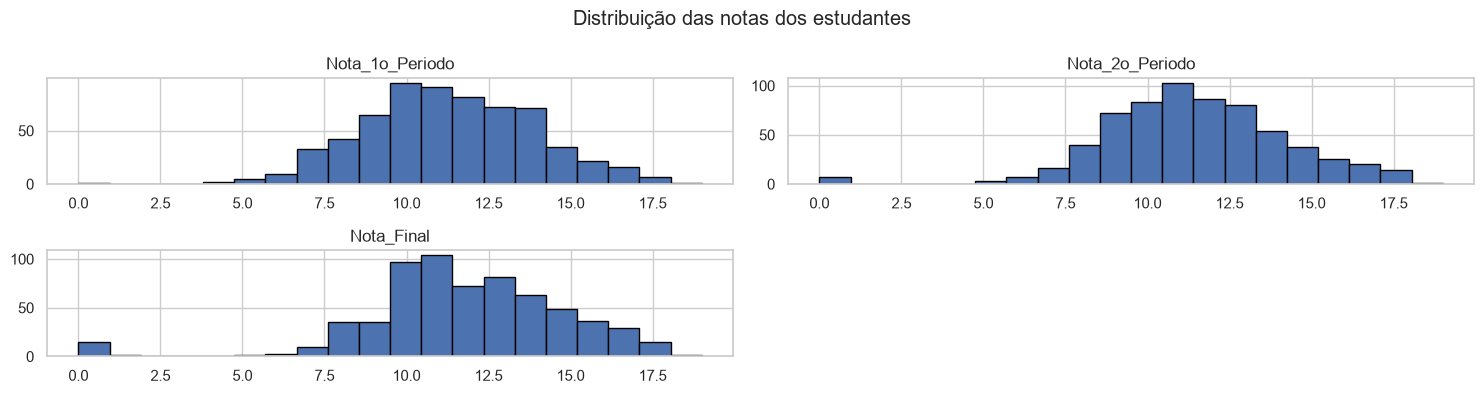

In [28]:
df[colunas_notas].hist(bins=20, figsize=(15,4), edgecolor="black")
plt.suptitle("Distribuição das notas dos estudantes")
plt.tight_layout(); plt.show()


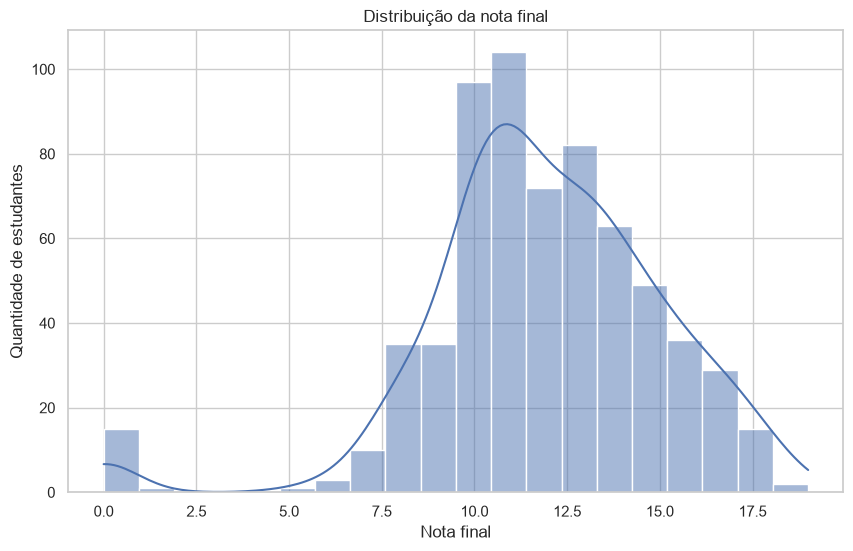

In [29]:
sns.histplot(data=df, x="Nota_Final", bins=20, kde=True)
plt.title("Distribuição da nota final"); plt.xlabel("Nota final"); plt.ylabel("Quantidade de estudantes"); plt.show()


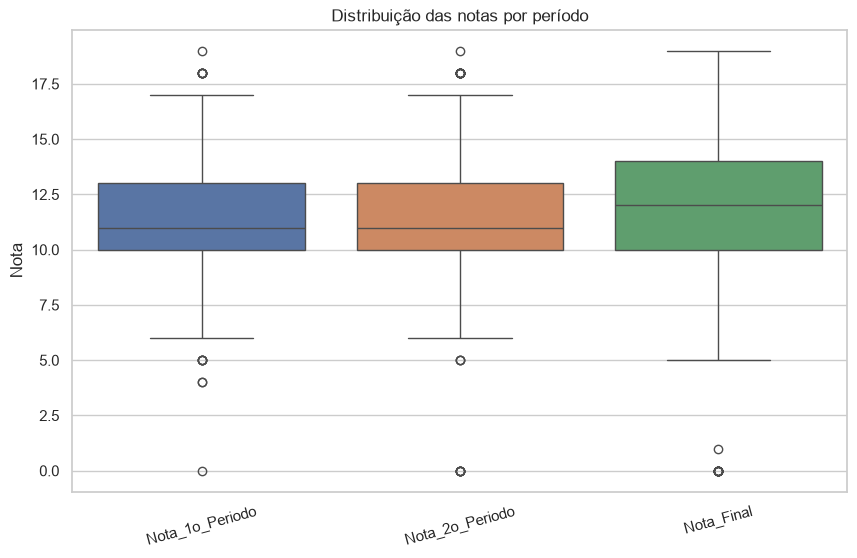

In [30]:
sns.boxplot(data=df[colunas_notas])
plt.title("Distribuição das notas por período"); plt.ylabel("Nota"); plt.xticks(rotation=15); plt.show()


### Notas iguais a zero

Serão apenas contabilizadas e observadas. Não serão recalculadas ou removidas automaticamente.


In [31]:
pd.DataFrame({
    "Quantidade_Zero": (df[colunas_notas] == 0).sum(),
    "Percentual_Zero": ((df[colunas_notas] == 0).mean()*100).round(2)
})


,Quantidade_Zero,Percentual_Zero
Nota_1o_Periodo,1,0.15
Nota_2o_Periodo,7,1.08
Nota_Final,15,2.31


In [32]:
df[df["Nota_Final"] == 0][["Escola","Sexo","Idade","Numero_de_Faltas","Nota_1o_Periodo","Nota_2o_Periodo","Nota_Final"]]


,Escola,Sexo,Idade,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
163,GP,Masculino,18,0,11,9,0
440,MS,Masculino,16,0,7,0,0
519,MS,Masculino,16,0,8,7,0
563,MS,Masculino,17,0,7,0,0
567,MS,Masculino,18,0,4,0,0
583,MS,Feminino,18,0,8,6,0
586,MS,Feminino,17,0,8,8,0
597,MS,Feminino,18,0,9,0,0
603,MS,Feminino,18,0,5,0,0
605,MS,Feminino,19,0,5,0,0


## 2.12 Faltas e outliers

Usamos histograma, boxplot e IQR. Um outlier estatístico não é automaticamente um erro.


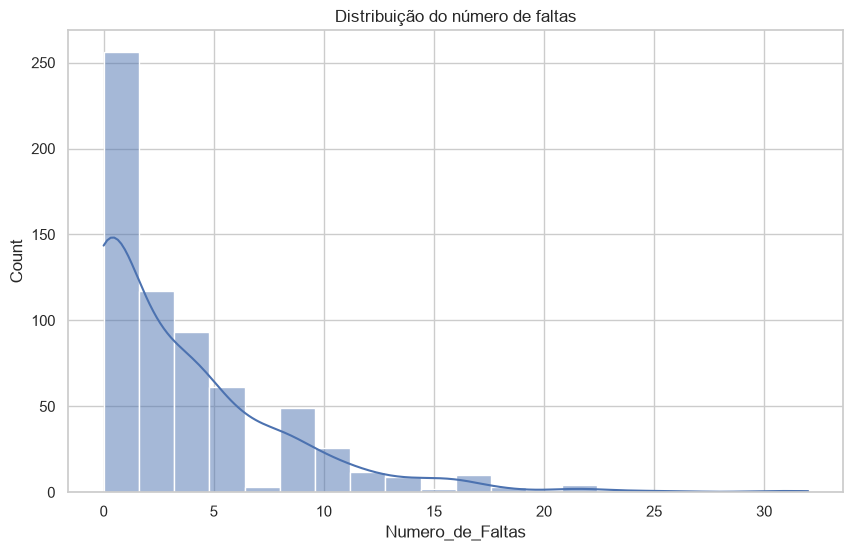

In [33]:
sns.histplot(data=df, x="Numero_de_Faltas", bins=20, kde=True)
plt.title("Distribuição do número de faltas"); plt.show()


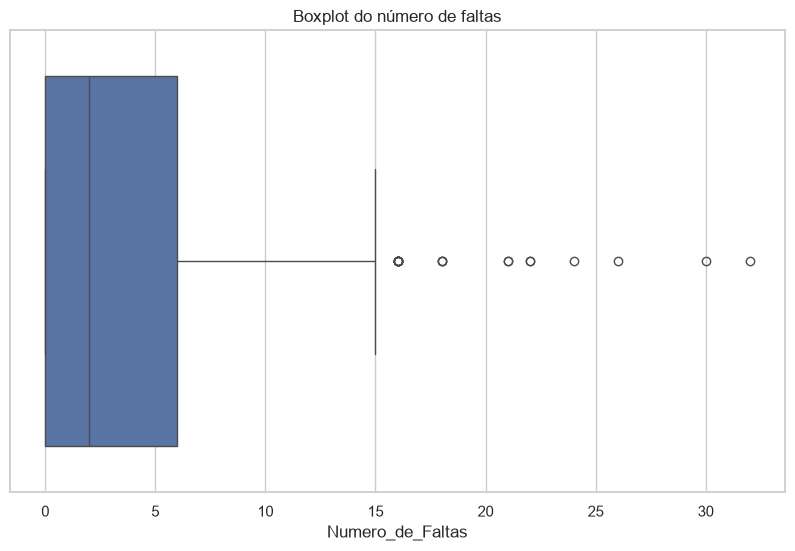

In [34]:
sns.boxplot(data=df, x="Numero_de_Faltas")
plt.title("Boxplot do número de faltas"); plt.show()


In [35]:
Q1 = df["Numero_de_Faltas"].quantile(.25); Q3 = df["Numero_de_Faltas"].quantile(.75); IQR = Q3-Q1
limite_inferior = Q1 - 1.5*IQR; limite_superior = Q3 + 1.5*IQR
faltas_atipicas = df[(df["Numero_de_Faltas"] < limite_inferior) | (df["Numero_de_Faltas"] > limite_superior)]
print("Q1:",Q1,"Q3:",Q3,"IQR:",IQR,"Limite superior:",limite_superior)
print("Casos atípicos:", faltas_atipicas.shape[0])
faltas_atipicas[["Numero_de_Faltas","Nota_Final"]].sort_values("Numero_de_Faltas",ascending=False).head(20)


Q1: 0.0 Q3: 6.0 IQR: 6.0 Limite superior: 15.0
Casos atípicos: 21


,Numero_de_Faltas,Nota_Final
197,32,14
212,30,16
256,26,8
150,24,9
155,22,6
325,22,10
217,21,13
413,21,10
326,18,13
397,18,14


## 2.13 Tempo de estudo e reprovações anteriores


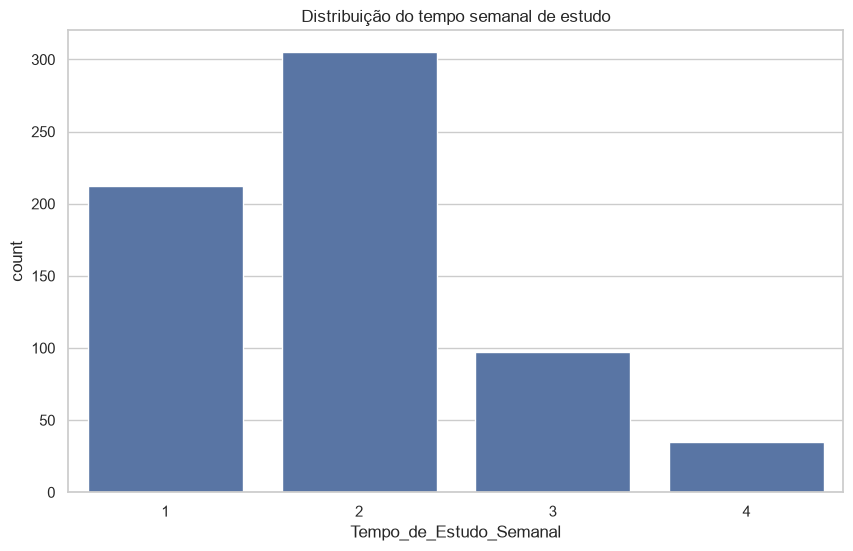

In [36]:
sns.countplot(data=df, x="Tempo_de_Estudo_Semanal", order=[1,2,3,4])
plt.title("Distribuição do tempo semanal de estudo"); plt.show()


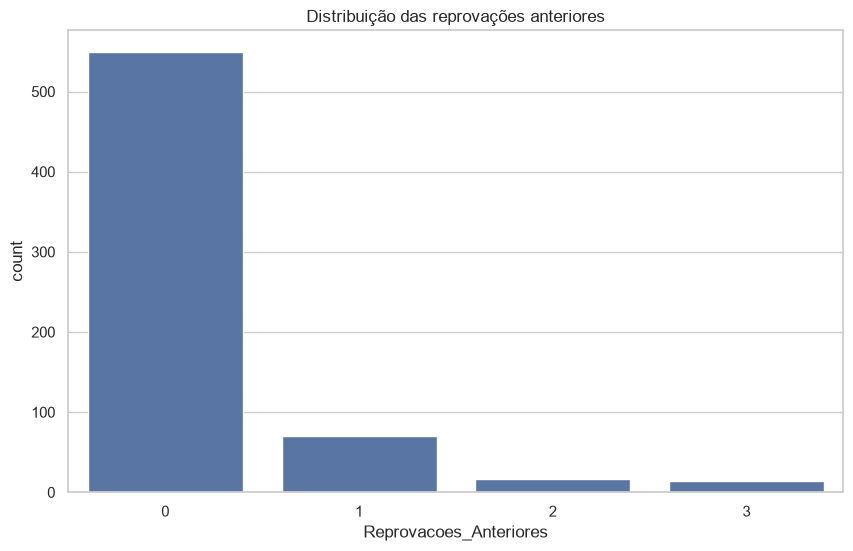

In [37]:
sns.countplot(data=df, x="Reprovacoes_Anteriores")
plt.title("Distribuição das reprovações anteriores"); plt.show()


## 2.14 Relações com o desempenho

Comparamos a nota final com tempo de estudo, reprovações, faltas e algumas variáveis categóricas.


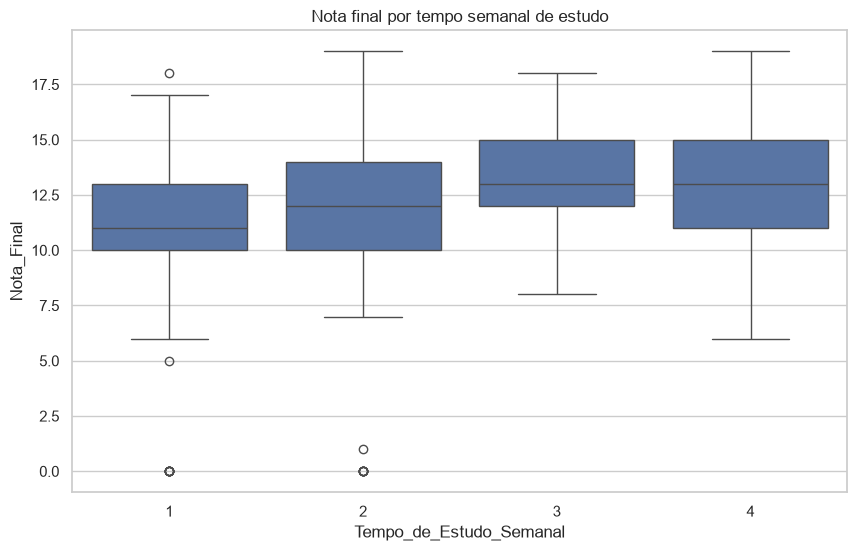

,count,mean,median,std
Tempo_de_Estudo_Semanal,,,,
1,212,10.84,11.0,3.22
2,305,12.09,12.0,3.24
3,97,13.23,13.0,2.50
4,35,13.06,13.0,3.04


In [38]:
sns.boxplot(data=df, x="Tempo_de_Estudo_Semanal", y="Nota_Final", order=[1,2,3,4]); plt.title("Nota final por tempo semanal de estudo"); plt.show()
df.groupby("Tempo_de_Estudo_Semanal")["Nota_Final"].agg(["count","mean","median","std"]).round(2)


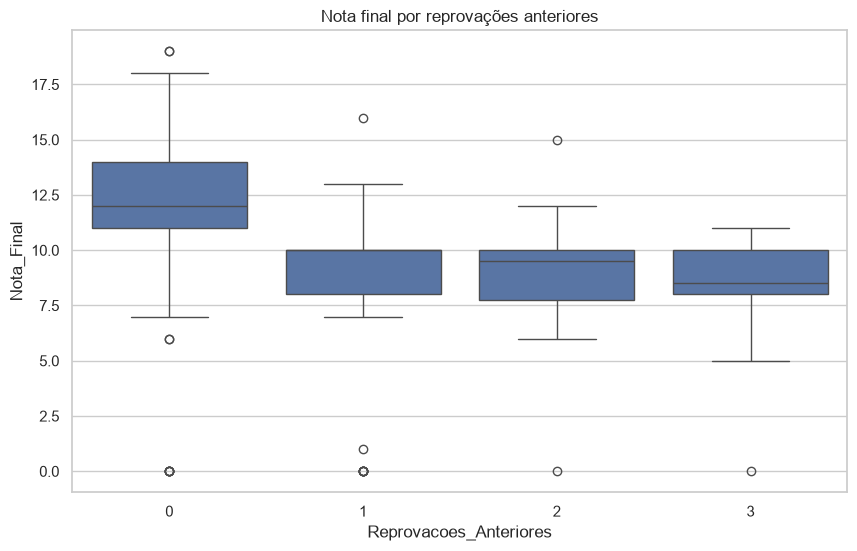

,count,mean,median,std
Reprovacoes_Anteriores,,,,
0,549,12.51,12.0,2.83
1,70,8.64,10.0,3.44
2,16,8.81,9.5,3.21
3,14,8.07,8.5,2.79


In [39]:
sns.boxplot(data=df, x="Reprovacoes_Anteriores", y="Nota_Final"); plt.title("Nota final por reprovações anteriores"); plt.show()
df.groupby("Reprovacoes_Anteriores")["Nota_Final"].agg(["count","mean","median","std"]).round(2)


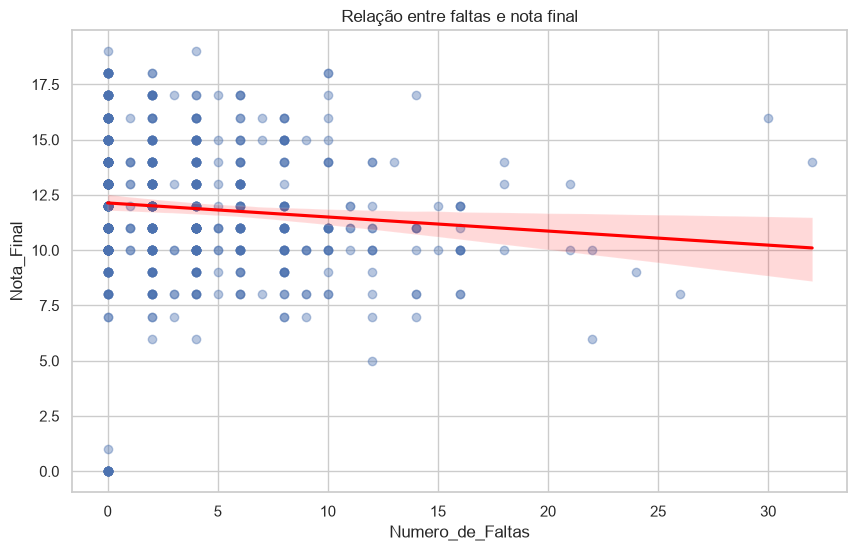

In [40]:
sns.regplot(data=df, x="Numero_de_Faltas", y="Nota_Final", scatter_kws={"alpha":.4}, line_kws={"color":"red"})
plt.title("Relação entre faltas e nota final"); plt.show()


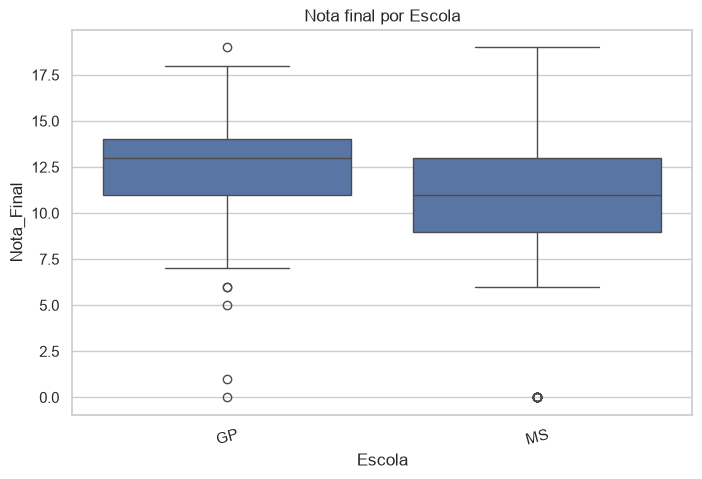

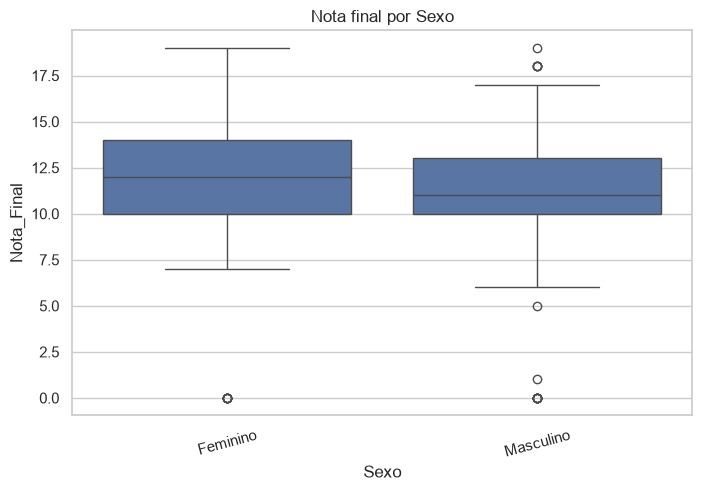

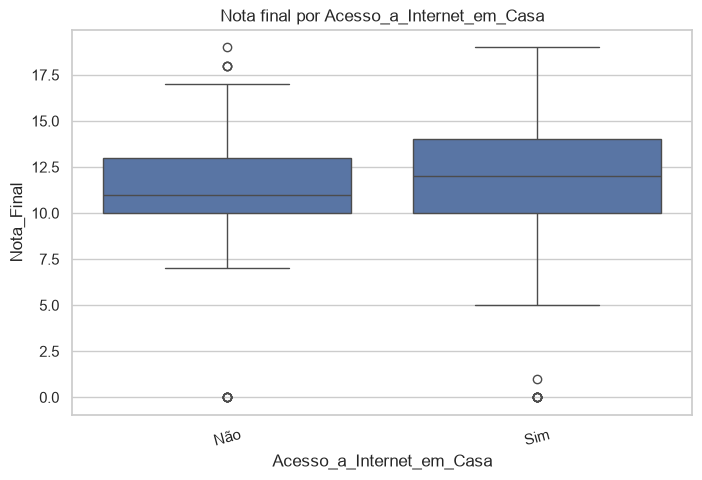

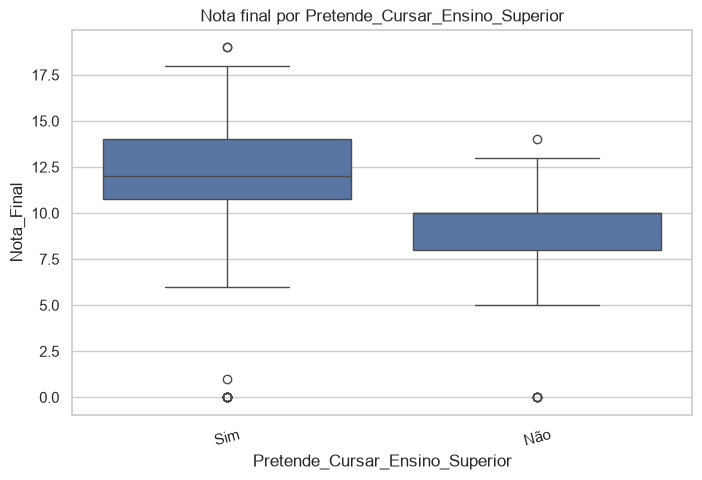

In [41]:
for coluna in ["Escola","Sexo","Acesso_a_Internet_em_Casa","Pretende_Cursar_Ensino_Superior"]:
    plt.figure(figsize=(8,5))
    sns.boxplot(data=df, x=coluna, y="Nota_Final")
    plt.title(f"Nota final por {coluna}")
    plt.xticks(rotation=15)
    plt.show()


## 2.15 Correlação

A correlação mede associação linear entre as variáveis numéricas. Variáveis ordinais exigem interpretação cautelosa.


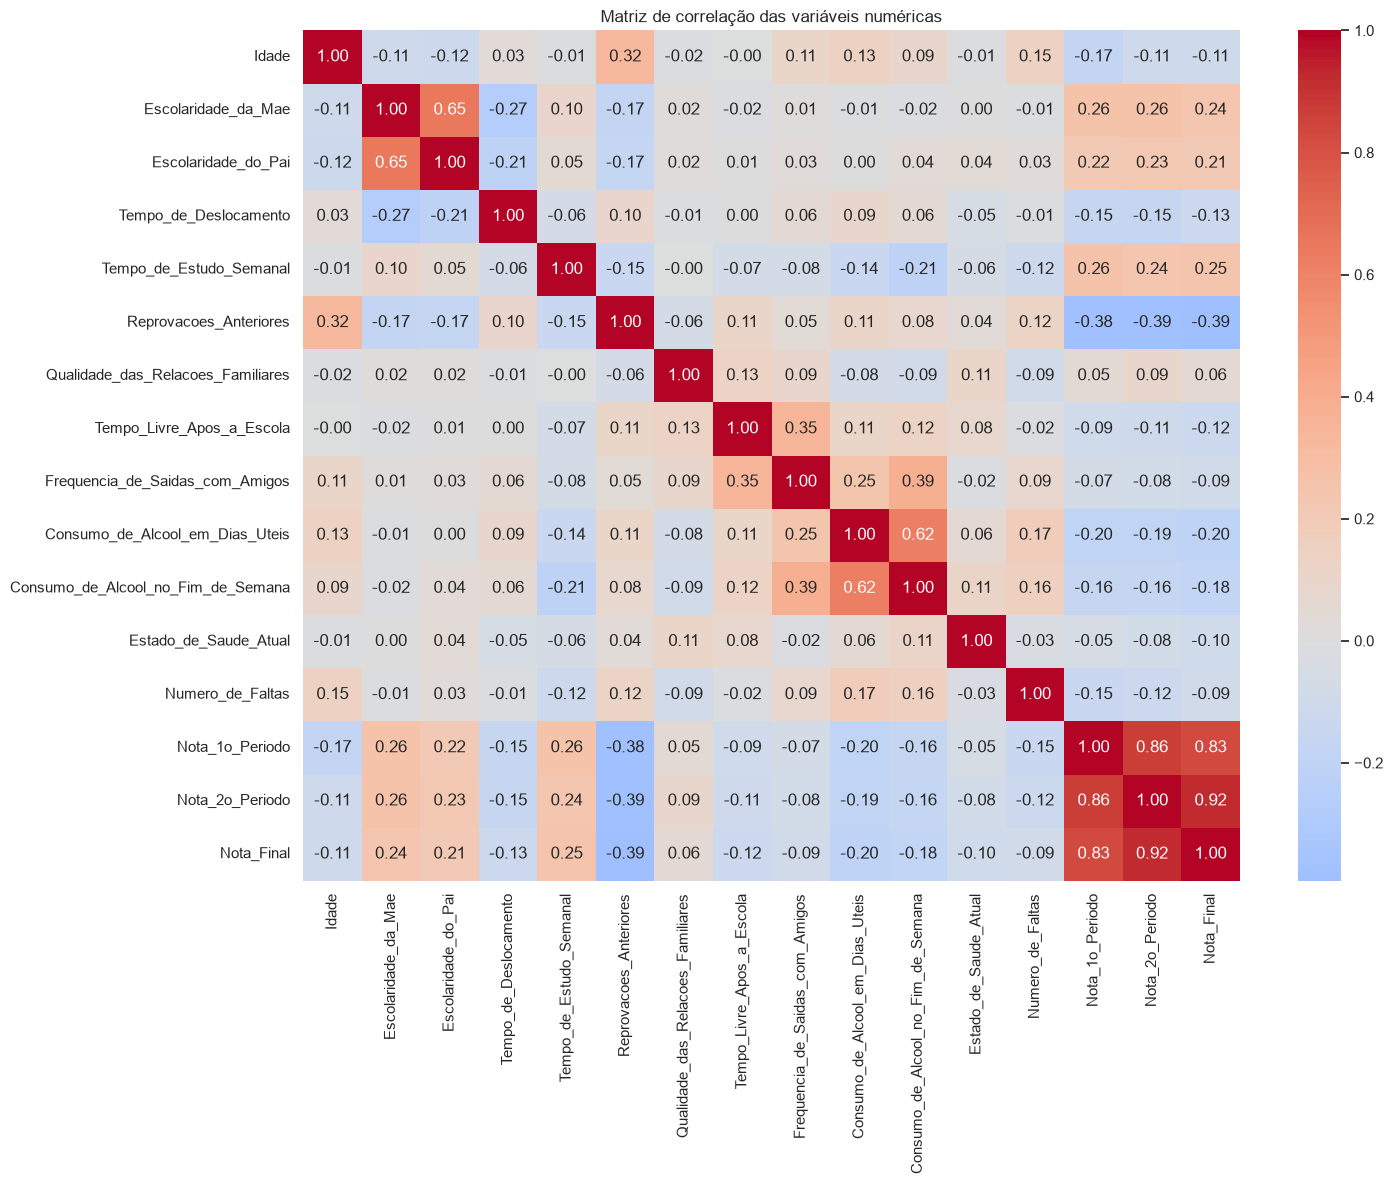

In [42]:
correlacao = df.select_dtypes(include="number").corr()
plt.figure(figsize=(15,12))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlação das variáveis numéricas")
plt.tight_layout(); plt.show()


In [43]:
correlacao_nota_final = correlacao["Nota_Final"].drop("Nota_Final").sort_values(ascending=False)
correlacao_nota_final


Nota_2o_Periodo                       0.918548
Nota_1o_Periodo                       0.826387
Tempo_de_Estudo_Semanal               0.249789
Escolaridade_da_Mae                   0.240151
Escolaridade_do_Pai                   0.211800
Qualidade_das_Relacoes_Familiares     0.063361
Frequencia_de_Saidas_com_Amigos      -0.087641
Numero_de_Faltas                     -0.091379
Estado_de_Saude_Atual                -0.098851
Idade                                -0.106505
Tempo_Livre_Apos_a_Escola            -0.122705
Tempo_de_Deslocamento                -0.127173
Consumo_de_Alcool_no_Fim_de_Semana   -0.176619
Consumo_de_Alcool_em_Dias_Uteis      -0.204719
Reprovacoes_Anteriores               -0.393316
Name: Nota_Final, dtype: float64

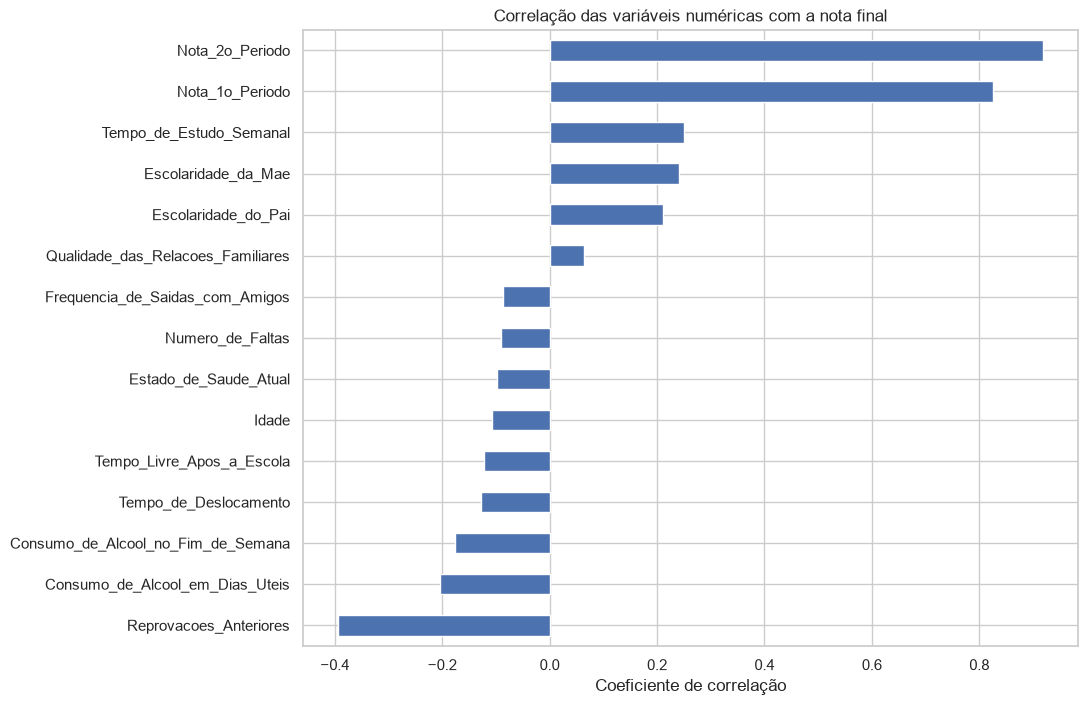

In [44]:
correlacao_nota_final.sort_values().plot(kind="barh", figsize=(10,8))
plt.title("Correlação das variáveis numéricas com a nota final"); plt.xlabel("Coeficiente de correlação"); plt.show()


**Atenção para a modelagem:** as notas do 1º e 2º períodos podem apresentar forte relação com a nota final. Se o objetivo for prever risco antes das avaliações, utilizá-las poderá causar vazamento de informação.


## 2.16 Situação final

Como análise complementar, consideramos nota final maior ou igual a 10 como aprovação.


In [45]:
df["Situacao_Final"] = np.where(df["Nota_Final"] >= 10, "Aprovado", "Reprovado")
print(df["Situacao_Final"].value_counts())
print((df["Situacao_Final"].value_counts(normalize=True)*100).round(2))


Situacao_Final
Aprovado     549
Reprovado    100
Name: count, dtype: int64
Situacao_Final
Aprovado     84.59
Reprovado    15.41
Name: proportion, dtype: float64


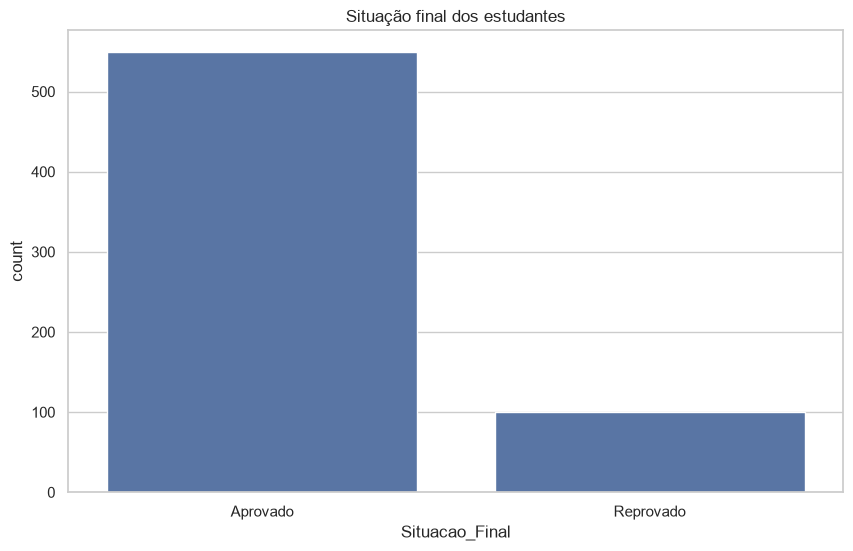

In [46]:
sns.countplot(data=df, x="Situacao_Final", order=["Aprovado","Reprovado"])
plt.title("Situação final dos estudantes"); plt.show()


### Taxa de aprovação por grupos


In [49]:
for coluna in ["Tempo_de_Estudo_Semanal","Escola","Acesso_a_Internet_em_Casa","Reprovacoes_Anteriores"]:
    print(" ", coluna)
    display(pd.crosstab(df[coluna], df["Situacao_Final"], normalize="index").mul(100).round(2))


  Tempo_de_Estudo_Semanal


Situacao_Final,Aprovado,Reprovado
Tempo_de_Estudo_Semanal,,
1,76.42,23.58
2,86.56,13.44
3,92.78,7.22
4,94.29,5.71


  Escola


Situacao_Final,Aprovado,Reprovado
Escola,,
GP,92.43,7.57
MS,69.91,30.09


  Acesso_a_Internet_em_Casa


Situacao_Final,Aprovado,Reprovado
Acesso_a_Internet_em_Casa,,
Não,78.81,21.19
Sim,86.35,13.65


  Reprovacoes_Anteriores


Situacao_Final,Aprovado,Reprovado
Reprovacoes_Anteriores,,
0,90.71,9.29
1,54.29,45.71
2,50.00,50.00
3,35.71,64.29


## 2.17 Codificação das variáveis categóricas

Criamos uma cópia para modelagem e transformamos categorias em valores numéricos.


In [50]:
df_modelagem = df.copy()
mapa_sim_nao = {"Não":0, "Sim":1}
colunas_sim_nao = ["Apoio_Educacional_da_Escola","Apoio_Educacional_Familiar","Aulas_Particulares_Pagas","Atividades_Extracurriculares","Frequentou_Educacao_Infantil","Pretende_Cursar_Ensino_Superior","Acesso_a_Internet_em_Casa","Relacionamento_Amoroso"]
for coluna in colunas_sim_nao:
    df_modelagem[coluna] = df_modelagem[coluna].map(mapa_sim_nao)
df_modelagem[colunas_sim_nao].isnull().sum()


Apoio_Educacional_da_Escola        0
Apoio_Educacional_Familiar         0
Aulas_Particulares_Pagas           0
Atividades_Extracurriculares       0
Frequentou_Educacao_Infantil       0
Pretende_Cursar_Ensino_Superior    0
Acesso_a_Internet_em_Casa          0
Relacionamento_Amoroso             0
dtype: int64

In [51]:
df_modelagem["Situacao_Final"] = df_modelagem["Situacao_Final"].map({"Reprovado":0,"Aprovado":1})
colunas_categoricas_restantes = df_modelagem.select_dtypes(include="object").columns.tolist()
df_codificado = pd.get_dummies(df_modelagem, columns=colunas_categoricas_restantes, drop_first=True, dtype=int)
print("Antes:", df.shape, "Depois:", df_codificado.shape)
df_codificado.head()


Antes: (649, 34) Depois: (649, 43)


,Idade,Escolaridade_da_Mae,Escolaridade_do_Pai,Tempo_de_Deslocamento,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Apoio_Educacional_da_Escola,Apoio_Educacional_Familiar,Aulas_Particulares_Pagas,Atividades_Extracurriculares,Frequentou_Educacao_Infantil,Pretende_Cursar_Ensino_Superior,Acesso_a_Internet_em_Casa,Relacionamento_Amoroso,Qualidade_das_Relacoes_Familiares,Tempo_Livre_Apos_a_Escola,Frequencia_de_Saidas_com_Amigos,Consumo_de_Alcool_em_Dias_Uteis,Consumo_de_Alcool_no_Fim_de_Semana,Estado_de_Saude_Atual,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final,Situacao_Final,Escola_MS,Sexo_Masculino,Tipo_de_Endereco_Urbano,Tamanho_da_Familia_Mais de 3,Situacao_dos_Pais_Separados,Ocupacao_da_Mae_Outro,Ocupacao_da_Mae_Professor(a),Ocupacao_da_Mae_Saude,Ocupacao_da_Mae_Servicos,Ocupacao_do_Pai_Outro,Ocupacao_do_Pai_Professor(a),Ocupacao_do_Pai_Saude,Ocupacao_do_Pai_Servicos,Motivo_da_Escolha_da_Escola_Preferencia pelo curso,Motivo_da_Escolha_da_Escola_Proximidade de casa,Motivo_da_Escolha_da_Escola_Reputacao da escola,Responsavel_Outro,Responsavel_Pai
0,18,4,4,2,2,0,1,0,0,0,1,1,0,0,4,3,4,1,1,3,4,0,11,11,1,0,0,1,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0
1,17,1,1,1,2,0,0,1,0,0,0,1,1,0,5,3,3,1,1,3,2,9,11,11,1,0,0,1,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1
2,15,1,1,1,2,0,1,0,0,0,1,1,1,0,4,3,2,2,3,3,6,12,13,12,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,15,4,2,1,3,0,0,1,0,1,1,1,1,1,3,2,2,1,1,5,0,14,14,14,1,0,0,1,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0
4,16,3,3,1,2,0,0,1,0,0,1,1,0,0,4,3,2,1,2,5,0,11,13,13,1,0,0,1,1,0,1,0,0,0,1,0,0,0,0,1,0,0,1


## 2.18 Padronização

A padronização é útil para modelos sensíveis à escala. Na modelagem definitiva, o `StandardScaler` deve ser ajustado somente nos dados de treino.


In [62]:

df_padronizado = df_codificado.copy()
colunas_para_padronizar = ["Idade","Numero_de_Faltas"]
scaler = StandardScaler()
df_padronizado[colunas_para_padronizar] = scaler.fit_transform(df_padronizado[colunas_para_padronizar])
df_padronizado[colunas_para_padronizar].describe().round(2)


,Idade,Numero_de_Faltas
count,649.00,649.00
mean,-0.00,0.00
std,1.00,1.00
min,-1.43,-0.79
25%,-0.61,-0.79
50%,0.21,-0.36
75%,1.03,0.50
max,4.32,6.11


## 2.19 Resumo da qualidade da base


In [64]:
resumo_qualidade = pd.DataFrame({
    "Indicador":["Quantidade de estudantes","Variáveis originais","Valores ausentes","Linhas duplicadas","Menor nota final","Maior nota final","Maior número de faltas"],
    "Resultado":[df.shape[0],33,df.isnull().sum().sum(),df.duplicated().sum(),df["Nota_Final"].min(),df["Nota_Final"].max(),df["Numero_de_Faltas"].max()]
})
resumo_qualidade


,Indicador,Resultado
0,Quantidade de estudantes,649
1,Variáveis originais,33
2,Valores ausentes,0
3,Linhas duplicadas,0
4,Menor nota final,0
5,Maior nota final,19
6,Maior número de faltas,32


## 2.20 Salvamento das bases processadas

Os resultados são salvos em novos arquivos, preservando o CSV original.


In [65]:
df.to_csv("estudantes_desempenho_tratado.csv", sep=";", index=False, encoding="utf-8-sig")
df_codificado.to_csv("estudantes_desempenho_codificado.csv", sep=";", index=False, encoding="utf-8-sig")
df_padronizado.to_csv("estudantes_desempenho_padronizado.csv", sep=";", index=False, encoding="utf-8-sig")


# Conclusão da Etapa 2

Foram examinados tipos, ausências, duplicidades, categorias, intervalos esperados e distribuições. Também foram analisadas as relações entre notas, faltas, tempo de estudo, reprovações e desempenho escolar.

Valores atípicos foram identificados sem exclusão automática. **Notas iguais a zero foram preservadas como valores válidos**, sem qualquer recalculo artificial.

Por fim, foram demonstradas a codificação das variáveis categóricas e a padronização de variáveis numéricas, preparando a base para as próximas etapas do projeto.
